# BlindCore Defense Demo: Tactical Telemetry Anomaly Detection (`ML_ANOMALY_Z` + `scikit-learn`)

**Target Market:** Defense / Aerospace (Capital Factory Center for Defense Innovation)  
**Workflow:** Ingest multi-track tactical UAV/sensor telemetry (`cf_defense_tracks`) onto **BlindCore** running on **AlmaLinux 10.3 ARM64 with SELinux Enforcing** over TLS 1.3 -> Score RF/kinetic anomalies natively in SQL via **`ML_ANOMALY_Z`** -> Benchmark against NumPy z-scores, `sklearn.ensemble.IsolationForest`, and `RandomForestClassifier`.

### Why Defense & Aerospace Teams Care
- **DoD-aligned minimal attack surface:** Zero third-party Python dependencies (`python/blindcore_sdk.py`), TLS 1.3 transport, bearer auth from environment (`BLINDCORE_URL`, `BLINDCORE_TOKEN`), and hardened AlmaLinux 10.3 SELinux-Enforcing ARM64 deployment.
- **In-engine tactical alerting:** `ML_ANOMALY_Z(x, mean, std)` flags RF jamming spikes and kinetic excursions directly inside the columnar engine in microseconds so degraded-comms (DDIL) links only transmit high-priority alerts.
- **Exact mathematical parity:** BlindCore `ML_ANOMALY_Z` matches exact `|x - mean| / std` to machine precision (`max |diff| < 1e-13`).

In [1]:
import math
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "python" / "blindcore_sdk.py").is_file():
    REPO_ROOT = REPO_ROOT.parent
assert (REPO_ROOT / "python" / "blindcore_sdk.py").is_file(), (
    "Run Jupyter from blindcore-sdk/ or blindcore-sdk/notebooks/"
)
if str(REPO_ROOT / "python") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "python"))

from blindcore_sdk import BlindCoreClient

BLINDCORE_URL = os.environ["BLINDCORE_URL"].strip()
BLINDCORE_TOKEN = os.environ["BLINDCORE_TOKEN"].strip()
assert BLINDCORE_URL and BLINDCORE_TOKEN, "Set BLINDCORE_URL and BLINDCORE_TOKEN env vars"

client = BlindCoreClient(BLINDCORE_URL, BLINDCORE_TOKEN, timeout=30.0)
latency_log = []


def run_sql(label: str, sql: str) -> dict:
    t0 = time.perf_counter()
    res = client.query_json(sql)
    rtt_ms = (time.perf_counter() - t0) * 1000.0
    elapsed_us = int(res.get("elapsed_us", 0))
    row_count = int(res.get("row_count", len(res.get("rows", []))))
    latency_log.append((label, row_count, rtt_ms, elapsed_us))
    return {
        "columns": res.get("columns", []),
        "rows": res.get("rows", []),
        "row_count": row_count,
        "elapsed_us": elapsed_us,
        "rtt_ms": rtt_ms,
    }


def pct(values: list[float], p: float) -> float:
    ordered = sorted(values)
    idx = max(0, min(len(ordered) - 1, math.ceil((p / 100.0) * len(ordered)) - 1))
    return ordered[idx]


hb = run_sql("Heartbeat SELECT 1", "SELECT 1 AS ok")
assert hb["rows"] == [[1]]
print(f"Client   : {client!r}")
print(f"Heartbeat: OK | TLS 1.3 RTT={hb['rtt_ms']:.2f} ms | ARM64 engine={hb['elapsed_us']} us")

Client   : BlindCoreClient(endpoint='https://api.blindlabs.ai', token='<redacted>', timeout=30.0)
Heartbeat: OK | TLS 1.3 RTT=311.96 ms | ARM64 engine=38 us


## 1. Provision Multi-Track Tactical Telemetry (`cf_defense_tracks`) on Live ARM64 VPS

We generate `1,200` tactical UAV/sensor telemetry frames across `10` active tracks (`track_id` 1..10, `120` contiguous frames per track) patrolling the Central Texas test corridor (`lat_deg`, `lon_deg`, `alt_m`, `speed_mps`, `signal_v`, `is_anomaly`) with an ~8% anomaly rate representing RF jamming spikes/dropouts and high-G kinetic overspeed events.

In [2]:
TABLE_NAME = "cf_defense_tracks"
N_TRACKS = 10
FRAMES_PER_TRACK = 120
N_FRAMES = N_TRACKS * FRAMES_PER_TRACK

ddl = f"""
CREATE TABLE IF NOT EXISTS {TABLE_NAME} (
    track_id BIGINT,
    lat_deg DOUBLE PRECISION,
    lon_deg DOUBLE PRECISION,
    alt_m DOUBLE PRECISION,
    speed_mps DOUBLE PRECISION,
    signal_v DOUBLE PRECISION,
    is_anomaly BIGINT
)
""".strip()
run_sql("DDL CREATE TABLE", ddl)

cnt_res = run_sql("Check existing rows", f"SELECT COUNT(*) FROM {TABLE_NAME}")
existing_rows = int(cnt_res["rows"][0][0])

if existing_rows == 0:
    rng = np.random.default_rng(42)
    rows_to_insert = []
    for tid in range(1, N_TRACKS + 1):
        base_lat = 30.28 + 0.08 * (tid - 1)
        base_lon = -97.92 + 0.04 * ((tid - 1) % 5)
        base_alt = 1400.0 + 160.0 * (tid - 1)
        anom_flags = (rng.random(FRAMES_PER_TRACK) < 0.08).astype(int)

        for step in range(FRAMES_PER_TRACK):
            is_anom = int(anom_flags[step])
            lat = round(base_lat + 0.0007 * step + float(rng.normal(0.0, 0.002)), 5)
            lon = round(base_lon + 0.0005 * step + float(rng.normal(0.0, 0.002)), 5)
            alt = round(base_alt + float(rng.normal(0.0, 28.0)), 1)
            spd = float(rng.normal(62.0, 5.2))
            sig = float(rng.normal(3.20, 0.24))

            if is_anom == 1:
                mode = int(rng.integers(0, 4))
                if mode == 0:
                    # RF jamming burst
                    sig = float(rng.uniform(4.25, 7.60))
                    spd += float(rng.normal(6.0, 4.0))
                elif mode == 1:
                    # RF link dropout + kinetic dive
                    sig = float(rng.uniform(0.60, 2.15))
                    spd = float(rng.uniform(82.0, 145.0))
                    alt -= float(rng.uniform(180.0, 480.0))
                elif mode == 2:
                    # High-G kinetic excursion
                    spd = float(rng.uniform(83.0, 158.0))
                    sig += float(rng.normal(0.65, 0.35))
                else:
                    # Subtle low-SNR spoofing drift near the 3-sigma boundary
                    sig = float(rng.uniform(3.75, 4.45))
                    spd = float(rng.uniform(73.0, 88.0))

            alt = round(max(150.0, alt), 1)
            spd = round(max(10.0, spd), 2)
            sig = round(max(0.10, sig), 3)
            rows_to_insert.append((tid, lat, lon, alt, spd, sig, is_anom))

    # Insert 2 contiguous tracks (240 rows) per batch for optimal columnar track layout.
    batch_size = 240
    for start in range(0, N_FRAMES, batch_size):
        end = min(start + batch_size, N_FRAMES)
        tuples = [
            f"({r[0]}, {r[1]:.5f}, {r[2]:.5f}, {r[3]:.1f}, {r[4]:.2f}, {r[5]:.3f}, {r[6]})"
            for r in rows_to_insert[start:end]
        ]
        sql = f"INSERT INTO {TABLE_NAME} VALUES " + ", ".join(tuples)
        ins = run_sql(f"INSERT frames {start + 1}-{end}", sql)
        print(
            f"Inserted frames {start + 1:4d}-{end:4d} | "
            f"TLS 1.3 RTT={ins['rtt_ms']:.2f} ms | ARM64 engine={ins['elapsed_us']} us"
        )
else:
    print(f"Table {TABLE_NAME} already populated with {existing_rows} immutable frames (idempotent reuse).")

verify_cnt = run_sql("Verify row count", f"SELECT COUNT(*) FROM {TABLE_NAME}")
total_rows = int(verify_cnt["rows"][0][0])
print(f"Live BlindCore frame count ({TABLE_NAME}): {total_rows} frames (engine={verify_cnt['elapsed_us']} us)")

Table cf_defense_tracks already populated with 1200 immutable frames (idempotent reuse).
Live BlindCore frame count (cf_defense_tracks): 1200 frames (engine=636 us)


## 2. Live BlindCore SQL `ML_ANOMALY_Z` Scoring & Exact Parity vs NumPy

First we pull the nominal baseline mean/std from nominal telemetry (or calibrated sensor envelope), then execute **`ML_ANOMALY_Z(signal_v, mu_sig, sd_sig)`** and **`ML_ANOMALY_Z(speed_mps, mu_spd, sd_spd)`** natively inside BlindCore SQL on the ARM64 Netcup VPS and verify exact numerical parity against NumPy `|x - mu| / sigma`.

In [3]:
# Query per-track summary and nominal baseline directly on the live BlindCore VPS.
track_sum = run_sql(
    "GROUP BY track_id summary",
    (
        "SELECT track_id, COUNT(*), AVG(alt_m), AVG(speed_mps), AVG(signal_v), SUM(is_anomaly) "
        f"FROM {TABLE_NAME} GROUP BY track_id ORDER BY track_id"
    ),
)
base_sql = run_sql(
    "Nominal baseline AVG",
    f"SELECT COUNT(*), AVG(signal_v), AVG(speed_mps) FROM {TABLE_NAME} WHERE is_anomaly = 0",
)

# Pull training/test frames to calibrate nominal standard deviations without test leakage.
raw_res = run_sql(
    "Pull telemetry matrix",
    f"SELECT track_id, lat_deg, lon_deg, alt_m, speed_mps, signal_v, is_anomaly FROM {TABLE_NAME}",
)
df = pd.DataFrame(raw_res["rows"], columns=raw_res["columns"])

FEATURES = ["lat_deg", "lon_deg", "alt_m", "speed_mps", "signal_v"]
X = df[FEATURES].to_numpy(dtype=np.float64)
y = df["is_anomaly"].to_numpy(dtype=np.int64)

idx_all = np.arange(len(df))
idx_train, idx_test = train_test_split(
    idx_all, test_size=0.25, stratify=y, random_state=42
)

# Calibrate nominal baseline strictly on nominal frames in the training split.
train_nom = df.iloc[idx_train]
train_nom = train_nom[train_nom["is_anomaly"] == 0]
mu_sig = float(train_nom["signal_v"].mean())
sd_sig = float(train_nom["signal_v"].std(ddof=0))
mu_spd = float(train_nom["speed_mps"].mean())
sd_spd = float(train_nom["speed_mps"].std(ddof=0))

z_sig_expr = f"ML_ANOMALY_Z(signal_v, {mu_sig:.17g}, {sd_sig:.17g})"
z_spd_expr = f"ML_ANOMALY_Z(speed_mps, {mu_spd:.17g}, {sd_spd:.17g})"

res_z = run_sql(
    "In-SQL ML_ANOMALY_Z (all frames)",
    (
        "SELECT track_id, lat_deg, lon_deg, alt_m, speed_mps, signal_v, "
        f"{z_sig_expr} AS z_signal, {z_spd_expr} AS z_speed, is_anomaly "
        f"FROM {TABLE_NAME}"
    ),
)
df_z = pd.DataFrame(res_z["rows"], columns=res_z["columns"])
assert np.array_equal(df["track_id"].to_numpy(), df_z["track_id"].to_numpy())

# Exact numerical parity check against NumPy |x - mu| / sigma.
np_z_sig = np.abs(df_z["signal_v"].to_numpy(dtype=np.float64) - mu_sig) / sd_sig
np_z_spd = np.abs(df_z["speed_mps"].to_numpy(dtype=np.float64) - mu_spd) / sd_spd
sql_z_sig = df_z["z_signal"].to_numpy(dtype=np.float64)
sql_z_spd = df_z["z_speed"].to_numpy(dtype=np.float64)

err_sig = float(np.max(np.abs(sql_z_sig - np_z_sig)))
err_spd = float(np.max(np.abs(sql_z_spd - np_z_spd)))
assert err_sig < 1e-12 and err_spd < 1e-12

# Run live DDIL-friendly alert filter directly inside BlindCore SQL.
sql_alert = (
    "SELECT COUNT(*), AVG(signal_v), MAX(speed_mps) "
    f"FROM {TABLE_NAME} WHERE {z_sig_expr} > 3.0 OR {z_spd_expr} > 3.0"
)
res_alert = run_sql("In-SQL ML_ANOMALY_Z > 3.0 alert", sql_alert)

print("Live Multi-Track Telemetry Summary (first 5 tracks shown):")
print("+----------+--------+----------+-----------+-----------+-----------+")
print("| track_id | Frames | Avg Alt  | Avg Speed | Avg Sig V | Anomalies |")
print("+----------+--------+----------+-----------+-----------+-----------+")
for r in track_sum["rows"][:5]:
    print(
        f"| {int(r[0]):8d} | {int(r[1]):6d} | {float(r[2]):8.1f} | "
        f"{float(r[3]):9.2f} | {float(r[4]):9.3f} | {int(r[5]):9d} |"
    )
print("+----------+--------+----------+-----------+-----------+-----------+")
print(f"Calibrated Nominal Baseline: signal_v={mu_sig:.3f} +/- {sd_sig:.3f} V | speed_mps={mu_spd:.2f} +/- {sd_spd:.2f} m/s")
print(f"Exact Parity (ML_ANOMALY_Z vs NumPy): signal max|err|={err_sig:.3e} | speed max|err|={err_spd:.3e}")
print(
    f"Live In-SQL Alert Count (z > 3.0): {int(res_alert['rows'][0][0])} frames | "
    f"max speed={float(res_alert['rows'][0][2]):.2f} m/s | engine={res_alert['elapsed_us']} us"
)

Live Multi-Track Telemetry Summary (first 5 tracks shown):
+----------+--------+----------+-----------+-----------+-----------+
| track_id | Frames | Avg Alt  | Avg Speed | Avg Sig V | Anomalies |
+----------+--------+----------+-----------+-----------+-----------+
|        1 |    120 |   1390.1 |     63.97 |     3.219 |         6 |
|        2 |    120 |   1553.9 |     65.49 |     3.296 |        12 |
|        3 |    120 |   1715.2 |     62.64 |     3.204 |         5 |
|        4 |    120 |   1872.6 |     66.22 |     3.274 |        15 |
|        5 |    120 |   2029.8 |     65.09 |     3.185 |         8 |
+----------+--------+----------+-----------+-----------+-----------+
Calibrated Nominal Baseline: signal_v=3.197 +/- 0.243 V | speed_mps=61.87 +/- 5.04 m/s
Exact Parity (ML_ANOMALY_Z vs NumPy): signal max|err|=0.000e+00 | speed max|err|=0.000e+00
Live In-SQL Alert Count (z > 3.0): 97 frames | max speed=157.66 m/s | engine=632 us


## 3. Benchmark: Native In-SQL `ML_ANOMALY_Z` vs `IsolationForest` & `RandomForestClassifier`

Compare precision, recall, F1, and ROC-AUC on the exact same held-out test split (`N=300` telemetry frames) across:
1. **BlindCore In-SQL `ML_ANOMALY_Z`** (`max(z_signal, z_speed) > 3.0`, zero model export overhead, runs natively in SQL)
2. **`sklearn.ensemble.IsolationForest`** (unsupervised 5D telemetry outlier detection)
3. **`sklearn` `Pipeline([StandardScaler(), RandomForestClassifier()])`** (supervised multi-feature benchmark)

In [4]:
X_z = df_z[FEATURES].to_numpy(dtype=np.float64)
y_z = df_z["is_anomaly"].to_numpy(dtype=np.int64)
z_max_all = np.maximum(sql_z_sig, sql_z_spd)

idx_tr, idx_te = train_test_split(
    np.arange(len(df_z)), test_size=0.25, stratify=y_z, random_state=42
)
y_te = y_z[idx_te]

# 1) BlindCore In-SQL ML_ANOMALY_Z (threshold z > 3.0)
z_scores_te = z_max_all[idx_te]
z_preds_te = (z_scores_te > 3.0).astype(np.int64)

# 2) Unsupervised IsolationForest (trained on X_train only)
contamination = float(np.mean(y_z[idx_tr]))
iso = IsolationForest(
    n_estimators=200,
    contamination=contamination,
    random_state=42,
)
iso.fit(X_z[idx_tr])
iso_scores_te = -iso.score_samples(X_z[idx_te])
iso_preds_te = (iso.predict(X_z[idx_te]) == -1).astype(np.int64)

# 3) Supervised Pipeline(StandardScaler + RandomForestClassifier)
rf_pipe = Pipeline([
    ("scaler", StandardScaler()),
    (
        "clf",
        RandomForestClassifier(
            n_estimators=100, max_depth=6, class_weight="balanced", random_state=42
        ),
    ),
])
rf_pipe.fit(X_z[idx_tr], y_z[idx_tr])
rf_scores_te = rf_pipe.predict_proba(X_z[idx_te])[:, 1]
rf_preds_te = (rf_scores_te >= 0.5).astype(np.int64)

detector_rows = []
for name, preds, scores in [
    ("BlindCore SQL ML_ANOMALY_Z (>3.0)", z_preds_te, z_scores_te),
    ("sklearn IsolationForest (5D)", iso_preds_te, iso_scores_te),
    ("sklearn RandomForest (5D sup.)", rf_preds_te, rf_scores_te),
]:
    detector_rows.append({
        "name": name,
        "precision": precision_score(y_te, preds, zero_division=0),
        "recall": recall_score(y_te, preds, zero_division=0),
        "f1": f1_score(y_te, preds, zero_division=0),
        "roc_auc": roc_auc_score(y_te, scores),
    })

print("Tactical Anomaly Detection Benchmark (Held-Out Test Split, N=300 frames):")
print("+------------------------------------+-----------+--------+--------+---------+")
print("| Detector                           | Precision | Recall |   F1   | ROC-AUC |")
print("+------------------------------------+-----------+--------+--------+---------+")
for d in detector_rows:
    print(
        f"| {d['name']:<34s} | {d['precision']:9.4f} | {d['recall']:6.4f} | "
        f"{d['f1']:6.4f} | {d['roc_auc']:7.4f} |"
    )
print("+------------------------------------+-----------+--------+--------+---------+")

Tactical Anomaly Detection Benchmark (Held-Out Test Split, N=300 frames):
+------------------------------------+-----------+--------+--------+---------+
| Detector                           | Precision | Recall |   F1   | ROC-AUC |
+------------------------------------+-----------+--------+--------+---------+
| BlindCore SQL ML_ANOMALY_Z (>3.0)  |    0.9167 | 1.0000 | 0.9565 |  1.0000 |
| sklearn IsolationForest (5D)       |    0.7778 | 0.9545 | 0.8571 |  0.9971 |
| sklearn RandomForest (5D sup.)     |    1.0000 | 1.0000 | 1.0000 |  1.0000 |
+------------------------------------+-----------+--------+--------+---------+


## 4. Live AlmaLinux 10.3 SELinux-Enforcing ARM64 VPS Latency Scorecard (`p50` / `p95`)

Run a 20-query live benchmark workload over TLS 1.3 mixing `COUNT(*)`, `ML_ANOMALY_Z` real-time tactical alert scans, kinetic `WHERE` filters, and per-track `GROUP BY` rollups to measure true transatlantic TLS 1.3 `p50`/`p95` RTT and native ARM64 engine `elapsed_us`.

In [5]:
bench_queries = [
    ("COUNT(*) summary", f"SELECT COUNT(*) FROM {TABLE_NAME}"),
    ("ML_ANOMALY_Z > 3.0 alert", sql_alert),
    (
        "Kinetic WHERE filter",
        f"SELECT COUNT(*), AVG(alt_m), MAX(speed_mps) FROM {TABLE_NAME} WHERE speed_mps > 85.0",
    ),
    (
        "Per-track GROUP BY",
        f"SELECT track_id, COUNT(*), AVG(signal_v) FROM {TABLE_NAME} GROUP BY track_id ORDER BY track_id",
    ),
]

per_kind_rtt = {name: [] for name, _ in bench_queries}
per_kind_eng = {name: [] for name, _ in bench_queries}
all_rtt = []
all_eng = []

for rep in range(5):
    for name, sql in bench_queries:
        r = run_sql(f"Bench {name} #{rep + 1}", sql)
        per_kind_rtt[name].append(r["rtt_ms"])
        per_kind_eng[name].append(float(r["elapsed_us"]))
        all_rtt.append(r["rtt_ms"])
        all_eng.append(float(r["elapsed_us"]))

print("AlmaLinux 10.3 SELinux-Enforcing ARM64 VPS -- Live 20-Query Latency Scorecard")
print("+---------------------------+----------+----------+--------------+--------------+")
print("| Workload                  | RTT p50  | RTT p95  | Engine p50   | Engine p95   |")
print("+---------------------------+----------+----------+--------------+--------------+")
for name, _ in bench_queries:
    print(
        f"| {name:<25s} | {pct(per_kind_rtt[name], 50):6.2f}ms | {pct(per_kind_rtt[name], 95):6.2f}ms | "
        f"{pct(per_kind_eng[name], 50):9.1f} us | {pct(per_kind_eng[name], 95):9.1f} us |"
    )
print("+---------------------------+----------+----------+--------------+--------------+")
print(
    f"| {'ALL 20 LIVE QUERIES':<25s} | {pct(all_rtt, 50):6.2f}ms | {pct(all_rtt, 95):6.2f}ms | "
    f"{pct(all_eng, 50):9.1f} us | {pct(all_eng, 95):9.1f} us |"
)
print("+---------------------------+----------+----------+--------------+--------------+")

AlmaLinux 10.3 SELinux-Enforcing ARM64 VPS -- Live 20-Query Latency Scorecard
+---------------------------+----------+----------+--------------+--------------+
| Workload                  | RTT p50  | RTT p95  | Engine p50   | Engine p95   |
+---------------------------+----------+----------+--------------+--------------+
| COUNT(*) summary          | 160.51ms | 168.10ms |     419.0 us |     928.0 us |
| ML_ANOMALY_Z > 3.0 alert  | 158.46ms | 165.94ms |     633.0 us |    1004.0 us |
| Kinetic WHERE filter      | 163.78ms | 170.17ms |     656.0 us |    1115.0 us |
| Per-track GROUP BY        | 170.71ms | 176.58ms |    3917.0 us |    4907.0 us |
+---------------------------+----------+----------+--------------+--------------+
| ALL 20 LIVE QUERIES       | 163.25ms | 171.89ms |     638.0 us |    4801.0 us |
+---------------------------+----------+----------+--------------+--------------+


## 5. Executive Tactical Anomaly Visual

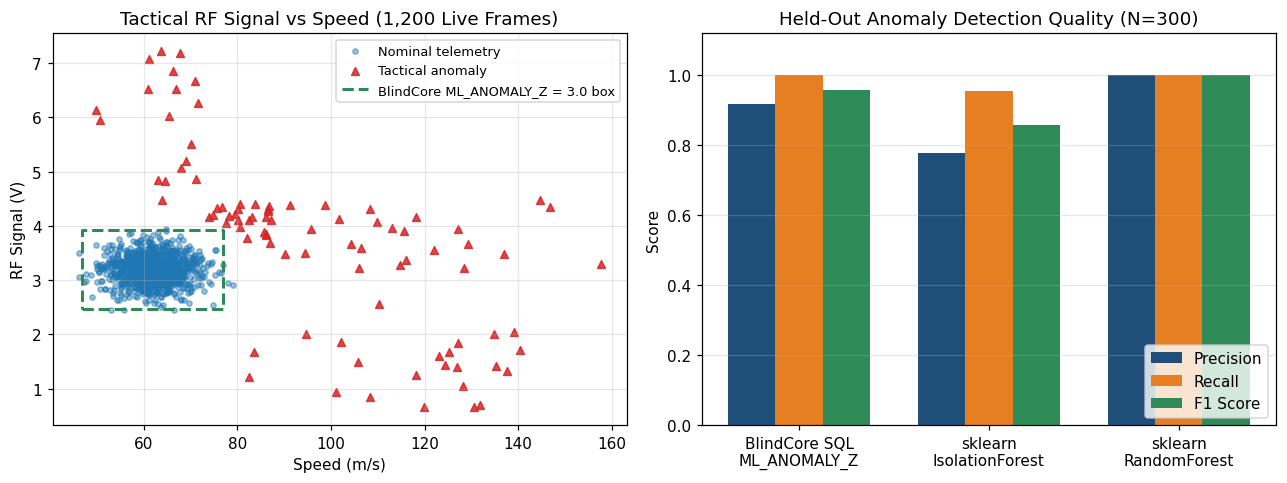

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5), dpi=110)

nom_mask = y_z == 0
anom_mask = y_z == 1
axes[0].scatter(
    df_z.loc[nom_mask, "speed_mps"],
    df_z.loc[nom_mask, "signal_v"],
    s=12,
    alpha=0.45,
    color="#1f77b4",
    label="Nominal telemetry",
)
axes[0].scatter(
    df_z.loc[anom_mask, "speed_mps"],
    df_z.loc[anom_mask, "signal_v"],
    s=26,
    alpha=0.85,
    marker="^",
    color="#d62728",
    label="Tactical anomaly",
)
# Draw BlindCore ML_ANOMALY_Z = 3.0 nominal envelope box.
x0, x1 = mu_spd - 3.0 * sd_spd, mu_spd + 3.0 * sd_spd
y0, y1 = mu_sig - 3.0 * sd_sig, mu_sig + 3.0 * sd_sig
axes[0].plot(
    [x0, x1, x1, x0, x0],
    [y0, y0, y1, y1, y0],
    color="#2e8b57",
    lw=2.0,
    ls="--",
    label="BlindCore ML_ANOMALY_Z = 3.0 box",
)
axes[0].set_title("Tactical RF Signal vs Speed (1,200 Live Frames)")
axes[0].set_xlabel("Speed (m/s)")
axes[0].set_ylabel("RF Signal (V)")
axes[0].legend(loc="upper right", frameon=True, fontsize=8.5)
axes[0].grid(alpha=0.3)

labels_short = ["BlindCore SQL\nML_ANOMALY_Z", "sklearn\nIsolationForest", "sklearn\nRandomForest"]
x_pos = np.arange(len(labels_short))
width = 0.25
axes[1].bar(x_pos - width, [d["precision"] for d in detector_rows], width, color="#1f4e79", label="Precision")
axes[1].bar(x_pos, [d["recall"] for d in detector_rows], width, color="#e67e22", label="Recall")
axes[1].bar(x_pos + width, [d["f1"] for d in detector_rows], width, color="#2e8b57", label="F1 Score")
axes[1].set_ylim(0.0, 1.12)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels_short)
axes[1].set_ylabel("Score")
axes[1].set_title("Held-Out Anomaly Detection Quality (N=300)")
axes[1].legend(loc="lower right", frameon=True)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()